# 02 · Neural Networks and Backpropagation

**Goal:** go from one neuron to a multi-layer network, understand *exactly* how backpropagation computes gradients, and train networks from scratch in NumPy.

**Contents**
1. From neurons to layers (matrix form)
2. The forward pass
3. Loss functions
4. Backpropagation = the chain rule on a computational graph
5. A tiny autograd engine (micrograd-style) you can read in one screen
6. A vectorised MLP with hand-written backprop
7. Gradient checking
8. Training: solving XOR and the two-moons problem
9. Optimisers: SGD, Momentum, Adam
10. Initialisation and learning rate
11. Cross-check against PyTorch autograd
12. Exercises

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

np.random.seed(0)
plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## 1. From neurons to layers

A **layer** is many neurons reading the same input. Stacking their weight vectors as rows of a matrix $W$ lets us compute all of them at once:

$$ \mathbf{z} = W\mathbf{x} + \mathbf{b}, \qquad \mathbf{a} = f(\mathbf{z}) \qquad\qquad W \in \mathbb{R}^{\text{out}\times\text{in}} $$

For a **batch** of $N$ samples stored as rows of $X \in \mathbb{R}^{N\times\text{in}}$ we write $Z = XW^\top + \mathbf{b}$. A **multi-layer perceptron (MLP)** chains layers:

```
x ──► [Linear W1,b1] ──► ReLU ──► [Linear W2,b2] ──► ReLU ──► [Linear W3,b3] ──► softmax ──► ŷ
       input layer          hidden layers (learn features)            output layer
```

**Universal approximation theorem:** one hidden layer with enough neurons can approximate any continuous function on a bounded domain. In practice, *deeper* networks need far fewer neurons for the same job because each layer reuses features built by the previous one.

## 2. The forward pass, by hand, on XOR

Notebook 01 showed that one neuron cannot compute XOR. Two hidden ReLU neurons are enough. The weights below were chosen by hand to show it is *possible*; section 8 will *learn* them.

* $h_1 = \text{ReLU}(x_1 + x_2)$ counts how many inputs are on
* $h_2 = \text{ReLU}(x_1 + x_2 - 1)$ fires only when both are on
* $\text{out} = h_1 - 2h_2$ gives 0, 1, 1, 0

In [2]:
relu = lambda z: np.maximum(0, z)
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
W1, b1 = np.array([[1.0, 1.0], [1.0, 1.0]]), np.array([0.0, -1.0])
W2, b2 = np.array([[1.0, -2.0]]), np.array([0.0])

H = relu(X_xor @ W1.T + b1)
out = H @ W2.T + b2
for x, h, o in zip(X_xor, H, out):
    print(f"x={x.astype(int)}  hidden={h}  output={o[0]:.0f}")

x=[0 0]  hidden=[0. 0.]  output=0
x=[0 1]  hidden=[1. 0.]  output=1
x=[1 0]  hidden=[1. 0.]  output=1
x=[1 1]  hidden=[2. 1.]  output=0


## 3. Loss functions

The loss is a single number that says how wrong the network is. Training minimises it.

| Task | Output layer | Loss |
|---|---|---|
| Regression | linear | Mean squared error $\frac1N\sum(\hat y - y)^2$ |
| Binary classification | sigmoid | Binary cross-entropy |
| Multi-class classification | softmax | Cross-entropy $-\frac1N\sum_i \log \hat p_{i,y_i}$ |
| Language modelling (GPT) | softmax over vocabulary | Cross-entropy on the next token |

Cross-entropy has a lovely property when combined with softmax: $\frac{\partial L}{\partial z_k} = \hat p_k - \mathbb{1}[k=y]$ (prediction minus one-hot target), which we will use below.

## 4. Backpropagation is the chain rule on a graph

Any computation can be drawn as a **computational graph**. Take $L = (wx + b - y)^2$:

```
 w ──┐
     (*)── u ──┐
 x ──┘         (+)── z ──┐
          b ───┘        (-)── e ──(^2)── L
                   y ───┘
```

* **Forward pass:** compute values left to right and remember them.
* **Backward pass:** start with $\frac{\partial L}{\partial L}=1$ and walk right to left. Each node multiplies the incoming gradient by its **local derivative** and passes it to its inputs (chain rule):

$$ \frac{\partial L}{\partial w} = \underbrace{\frac{\partial L}{\partial e}}_{2e}\cdot\underbrace{\frac{\partial e}{\partial z}}_{1}\cdot\underbrace{\frac{\partial z}{\partial u}}_{1}\cdot\underbrace{\frac{\partial u}{\partial w}}_{x} = 2e\,x $$

If a value feeds several nodes, its gradients from each path are **summed**. That is all backpropagation is (Rumelhart, Hinton & Williams, 1986). Its power is efficiency: one backward pass gives the gradient with respect to **all** parameters at roughly the cost of one forward pass, whether there are 10 or 10<sup>12</sup> of them.

## 5. A tiny autograd engine

Below is a scalar automatic-differentiation engine in about 50 lines, inspired by Andrej Karpathy's *micrograd*. Every `Value` remembers its parents and a `_backward` closure that applies the local chain-rule step. PyTorch's `loss.backward()` does exactly this, just on tensors and in C++/CUDA.

In [3]:
class Value:
    def __init__(self, data, parents=(), op=""):
        self.data, self.grad = float(data), 0.0
        self._parents, self._op = parents, op
        self._backward = lambda: None

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), "+")
        def _backward():
            self.grad += out.grad            # d(a+b)/da = 1
            other.grad += out.grad           # d(a+b)/db = 1
        out._backward = _backward
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), "*")
        def _backward():
            self.grad += other.data * out.grad   # d(ab)/da = b
            other.grad += self.data * out.grad   # d(ab)/db = a
        out._backward = _backward
        return out

    def __pow__(self, k):
        out = Value(self.data ** k, (self,), f"**{k}")
        def _backward():
            self.grad += k * self.data ** (k - 1) * out.grad
        out._backward = _backward
        return out

    def relu(self):
        out = Value(max(0.0, self.data), (self,), "relu")
        def _backward():
            self.grad += (out.data > 0) * out.grad
        out._backward = _backward
        return out

    def tanh(self):
        t = np.tanh(self.data)
        out = Value(t, (self,), "tanh")
        def _backward():
            self.grad += (1 - t ** 2) * out.grad
        out._backward = _backward
        return out

    __radd__ = __add__
    __rmul__ = __mul__
    def __neg__(self):            return self * -1
    def __sub__(self, other):     return self + (-other)
    def __rsub__(self, other):    return (-self) + other

    def backward(self):
        # topological order guarantees a node's grad is complete before it propagates further
        order, seen = [], set()
        def build(v):
            if v not in seen:
                seen.add(v)
                for p in v._parents:
                    build(p)
                order.append(v)
        build(self)
        self.grad = 1.0
        for v in reversed(order):
            v._backward()

    def __repr__(self):
        return f"Value(data={self.data:.4f}, grad={self.grad:.4f})"

# The example from section 4
w, x, b, y = Value(2.0), Value(3.0), Value(1.0), Value(4.0)
L = (w * x + b - y) ** 2
L.backward()
e = 2 * 3 + 1 - 4
print("L =", L.data, "| dL/dw =", w.grad, "(expected 2*e*x =", 2 * e * 3, ") | dL/db =", b.grad, "(expected 2*e =", 2 * e, ")")

L = 9.0 | dL/dw = 18.0 (expected 2*e*x = 18 ) | dL/db = 6.0 (expected 2*e = 6 )


### Training a tiny MLP with our engine

Neurons, layers and an MLP built entirely from `Value` objects. Slow (pure Python, one scalar at a time) but every gradient is computed by the code above.

parameters: 37
predictions: [-1.0, 1.0, 1.0, -1.0] targets: [-1.0, 1.0, 1.0, -1.0]


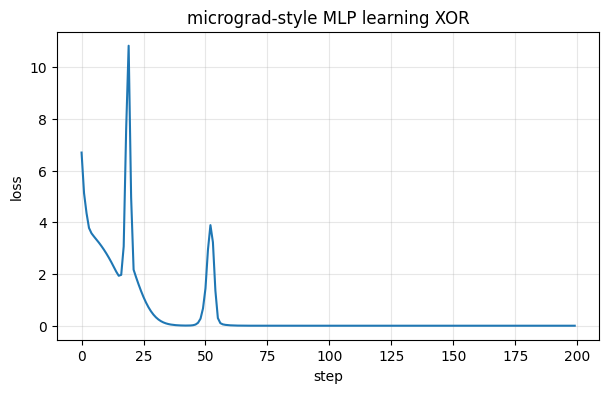

In [4]:
import random
random.seed(1)

class VNeuron:
    def __init__(self, n_in, act=True):
        self.w = [Value(random.uniform(-1, 1)) for _ in range(n_in)]
        self.b = Value(0.0)
        self.act = act
    def __call__(self, x):
        z = sum((wi * xi for wi, xi in zip(self.w, x)), self.b)
        return z.tanh() if self.act else z
    def parameters(self):
        return self.w + [self.b]

class VMLP:
    def __init__(self, sizes):
        self.layers = [[VNeuron(sizes[i], act=(i < len(sizes) - 2)) for _ in range(sizes[i + 1])]
                       for i in range(len(sizes) - 1)]
    def __call__(self, x):
        for layer in self.layers:
            x = [n(x) for n in layer]
        return x[0]
    def parameters(self):
        return [p for layer in self.layers for n in layer for p in n.parameters()]

net = VMLP([2, 4, 4, 1])
targets = [-1.0, 1.0, 1.0, -1.0]                    # XOR with labels in {-1, +1}
losses = []
for step in range(200):
    preds = [net(list(map(Value, x))) for x in X_xor]
    loss = sum(((p - t) ** 2 for p, t in zip(preds, targets)), Value(0.0))
    for p in net.parameters():
        p.grad = 0.0                                 # gradients accumulate, so reset them
    loss.backward()
    for p in net.parameters():
        p.data -= 0.05 * p.grad
    losses.append(loss.data)

print("parameters:", len(net.parameters()))
print("predictions:", [round(p.data, 3) for p in preds], "targets:", targets)
plt.plot(losses); plt.title("micrograd-style MLP learning XOR"); plt.xlabel("step"); plt.ylabel("loss"); plt.show()

## 6. A vectorised MLP with hand-written backprop

Scalars are great for understanding, terrible for speed. Real networks work with **matrices**. For a linear layer $Z = XW^\top + \mathbf{b}$ with upstream gradient $G = \partial L/\partial Z$:

$$ \frac{\partial L}{\partial W} = G^\top X, \qquad \frac{\partial L}{\partial \mathbf{b}} = \sum_{\text{batch}} G, \qquad \frac{\partial L}{\partial X} = G\,W $$

A shape check is the easiest way to remember these: $\partial L/\partial W$ must have the shape of $W$.

For an element-wise activation $A = f(Z)$: $\;\partial L/\partial Z = \partial L/\partial A \odot f'(Z)$.

Each layer below implements `forward` (caching what backward needs) and `backward` (returns the gradient for the previous layer and stores gradients for its own parameters). This is precisely the design of PyTorch's `nn.Module` + `autograd.Function`.

In [5]:
class Linear:
    def __init__(self, n_in, n_out, init="he"):
        scale = np.sqrt(2.0 / n_in) if init == "he" else (0.01 if init == "small" else 1.0)
        self.W = np.random.randn(n_out, n_in) * scale
        self.b = np.zeros(n_out)
    def forward(self, X):
        self.X = X
        return X @ self.W.T + self.b
    def backward(self, G):
        self.dW = G.T @ self.X
        self.db = G.sum(axis=0)
        return G @ self.W
    def params(self):
        return [(self.W, "dW"), (self.b, "db")]

class ReLU:
    def forward(self, Z):
        self.mask = Z > 0
        return Z * self.mask
    def backward(self, G):
        return G * self.mask
    def params(self):
        return []

class Tanh:
    def forward(self, Z):
        self.A = np.tanh(Z)
        return self.A
    def backward(self, G):
        return G * (1 - self.A ** 2)
    def params(self):
        return []

class SoftmaxCrossEntropy:
    # Fused for numerical stability; gradient is (p - onehot) / N
    def forward(self, logits, y):
        z = logits - logits.max(axis=1, keepdims=True)
        self.p = np.exp(z) / np.exp(z).sum(axis=1, keepdims=True)
        self.y = y
        return -np.log(self.p[np.arange(len(y)), y] + 1e-12).mean()
    def backward(self):
        G = self.p.copy()
        G[np.arange(len(self.y)), self.y] -= 1
        return G / len(self.y)

class MLP:
    def __init__(self, sizes, act=ReLU, init="he"):
        self.layers = []
        for i in range(len(sizes) - 1):
            self.layers.append(Linear(sizes[i], sizes[i + 1], init))
            if i < len(sizes) - 2:
                self.layers.append(act())
        self.loss_fn = SoftmaxCrossEntropy()
    def forward(self, X):
        for layer in self.layers:
            X = layer.forward(X)
        return X
    def loss(self, X, y):
        return self.loss_fn.forward(self.forward(X), y)
    def backward(self):
        G = self.loss_fn.backward()
        for layer in reversed(self.layers):     # the "back" in backpropagation
            G = layer.backward(G)
    def params(self):
        return [(layer, p, g) for layer in self.layers for p, g in layer.params()]
    def predict(self, X):
        return self.forward(X).argmax(axis=1)

net = MLP([2, 8, 2])
print([type(l).__name__ for l in net.layers])

['Linear', 'ReLU', 'Linear']


## 7. Gradient checking

Hand-written backprop is easy to get subtly wrong. We compare each analytic gradient with a central finite difference. A relative error below ~1e-6 means the implementation is correct.

In [6]:
def grad_check(net, X, y, h=1e-5):
    net.loss(X, y); net.backward()
    worst = 0.0
    for layer, P, gname in net.params():
        analytic = getattr(layer, gname)
        numeric = np.zeros_like(P)
        it = np.nditer(P, flags=["multi_index"])
        for _ in it:
            idx = it.multi_index
            old = P[idx]
            P[idx] = old + h; lp = net.loss(X, y)
            P[idx] = old - h; lm = net.loss(X, y)
            P[idx] = old
            numeric[idx] = (lp - lm) / (2 * h)
        rel = np.abs(analytic - numeric).max() / (np.abs(analytic).max() + np.abs(numeric).max() + 1e-12)
        worst = max(worst, rel)
    return worst

Xc, yc = make_moons(20, noise=0.2, random_state=0)
print("max relative error, ReLU net:", f"{grad_check(MLP([2, 5, 4, 2]), Xc, yc):.2e}")
print("max relative error, Tanh net:", f"{grad_check(MLP([2, 5, 4, 2], act=Tanh), Xc, yc):.2e}")

max relative error, ReLU net: 2.16e-10
max relative error, Tanh net: 3.87e-11


## 8. Training

The training loop is the same in every deep learning project, from this toy to GPT:

```
for each epoch:
    for each mini-batch (X, y):
        loss = forward(X, y)          # 1. predict and measure error
        backward()                    # 2. gradients of loss w.r.t. every parameter
        optimizer.step()              # 3. move parameters downhill
```

### 8a. XOR, learned instead of hand-crafted

Two hidden neurons are *enough* in theory (section 2), but gradient descent from an unlucky random start can get stuck with that little capacity (for example, a ReLU that dies). A wider layer gives the optimiser many more routes to a solution. This "over-parameterise, then optimise" effect is one reason large networks train so well.

In [7]:
def sgd_step(net, lr):
    for layer, P, gname in net.params():
        P -= lr * getattr(layer, gname)

y_xor = np.array([0, 1, 1, 0])

def train_xor(hidden, seed, epochs=1000, lr=0.2):
    np.random.seed(seed)
    net = MLP([2, hidden, 2])
    for epoch in range(epochs):
        loss = net.loss(X_xor, y_xor); net.backward(); sgd_step(net, lr)
    return net, loss

net, loss = train_xor(16, seed=0)
print(f"one run, 16 hidden: final loss {loss:.4f}; predictions {net.predict(X_xor)} vs targets {y_xor}\n")
for hidden in [2, 4, 16]:
    solved = sum((train_xor(hidden, seed)[0].predict(X_xor) == y_xor).all() for seed in range(20))
    print(f"hidden={hidden:2d}: solved XOR in {solved}/20 random initialisations")

one run, 16 hidden: final loss 0.0022; predictions [0 1 1 0] vs targets [0 1 1 0]



hidden= 2: solved XOR in 3/20 random initialisations


hidden= 4: solved XOR in 10/20 random initialisations


hidden=16: solved XOR in 20/20 random initialisations


### 8b. Two moons: a non-linear decision boundary

Mini-batches, a train/test split, and a plot of how the boundary evolves.

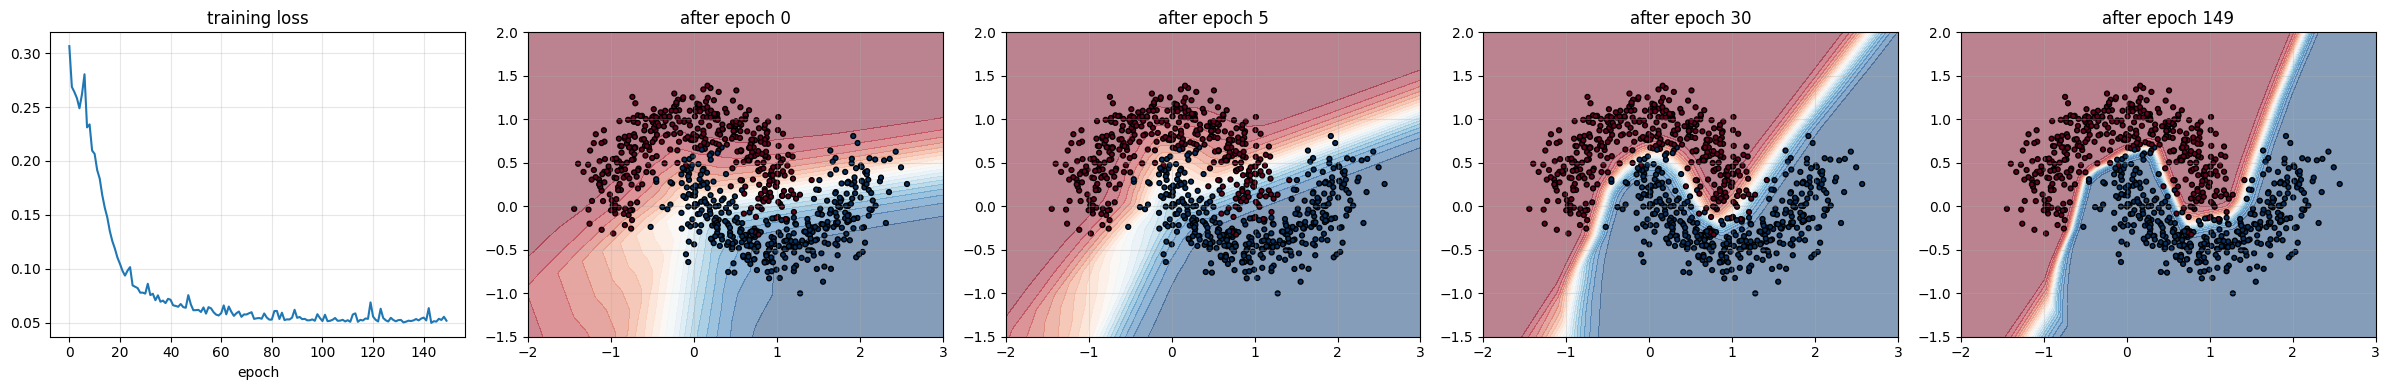

train acc 97.9% | test acc 97.5%


In [8]:
X, y = make_moons(1000, noise=0.2, random_state=42)
idx = np.random.permutation(len(X))
Xtr, ytr, Xte, yte = X[idx[:800]], y[idx[:800]], X[idx[800:]], y[idx[800:]]

def plot_boundary(ax, net, X, y, title):
    xx, yy = np.meshgrid(np.linspace(-2, 3, 250), np.linspace(-1.5, 2, 250))
    logits = net.forward(np.c_[xx.ravel(), yy.ravel()])
    p = np.exp(logits - logits.max(1, keepdims=True)); p /= p.sum(1, keepdims=True)
    ax.contourf(xx, yy, p[:, 1].reshape(xx.shape), levels=20, cmap="RdBu", alpha=0.5)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="RdBu", edgecolors="k", s=12)
    ax.set_title(title)

def train(net, step_fn, epochs=100, batch=32, verbose=False, snapshots=()):
    hist, snaps = [], {}
    for ep in range(epochs):
        perm = np.random.permutation(len(Xtr))
        for i in range(0, len(Xtr), batch):
            b = perm[i:i + batch]
            net.loss(Xtr[b], ytr[b]); net.backward(); step_fn(net)
        hist.append(net.loss(Xtr, ytr))
        if ep in snapshots:
            snaps[ep] = [(P.copy()) for _, P, _ in net.params()]
    return hist, snaps

np.random.seed(0)
net = MLP([2, 32, 32, 2])
hist, snaps = train(net, lambda n: sgd_step(n, 0.1), epochs=150, snapshots=(0, 5, 30, 149))

fig, axes = plt.subplots(1, 5, figsize=(24, 4))
axes[0].plot(hist); axes[0].set_title("training loss"); axes[0].set_xlabel("epoch")
final = [P.copy() for _, P, _ in net.params()]
for ax, (ep, params) in zip(axes[1:], snaps.items()):
    for (_, P, _), saved in zip(net.params(), params):
        P[...] = saved
    plot_boundary(ax, net, Xtr, ytr, f"after epoch {ep}")
for (_, P, _), saved in zip(net.params(), final):
    P[...] = saved
plt.tight_layout(); plt.show()
print(f"train acc {(net.predict(Xtr) == ytr).mean():.1%} | test acc {(net.predict(Xte) == yte).mean():.1%}")

### What did the hidden layer learn?

Each first-layer neuron draws one line (notebook 01). The second layer combines those half-planes into curved regions. Below: the activation of a few first-layer neurons over the input space.

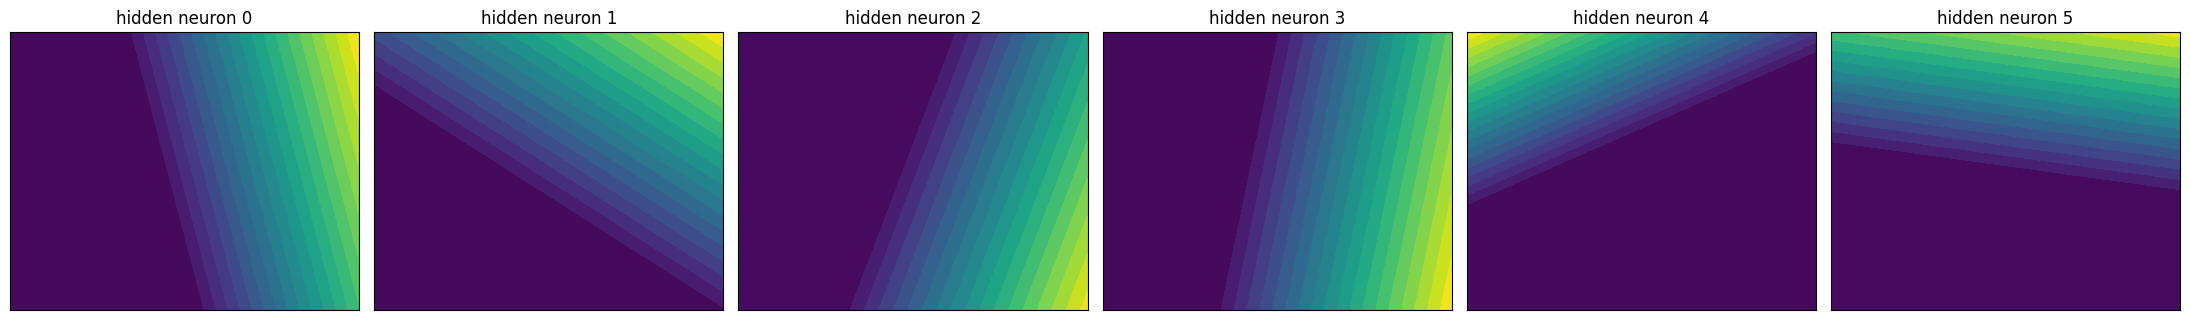

In [9]:
xx, yy = np.meshgrid(np.linspace(-2, 3, 150), np.linspace(-1.5, 2, 150))
grid = np.c_[xx.ravel(), yy.ravel()]
H1 = np.maximum(0, grid @ net.layers[0].W.T + net.layers[0].b)
fig, axes = plt.subplots(1, 6, figsize=(22, 3.3))
for k, ax in enumerate(axes):
    ax.contourf(xx, yy, H1[:, k].reshape(xx.shape), levels=20, cmap="viridis")
    ax.set_title(f"hidden neuron {k}"); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## 9. Optimisers

Plain SGD uses $\theta \leftarrow \theta - \eta\, g$. Two improvements power almost all modern training:

* **Momentum:** keep a running average of gradients, $v \leftarrow \beta v + g$, step along $v$. Like a heavy ball, it speeds through flat valleys and damps zig-zags.
* **Adam** (Kingma & Ba 2014): momentum *plus* a per-parameter scale from the running average of squared gradients, so each parameter gets its own effective learning rate. GPT-style models use **AdamW** (Adam + decoupled weight decay).

$$ m \leftarrow \beta_1 m + (1-\beta_1) g,\quad v \leftarrow \beta_2 v + (1-\beta_2) g^2,\quad \theta \leftarrow \theta - \eta\,\frac{\hat m}{\sqrt{\hat v}+\epsilon} $$

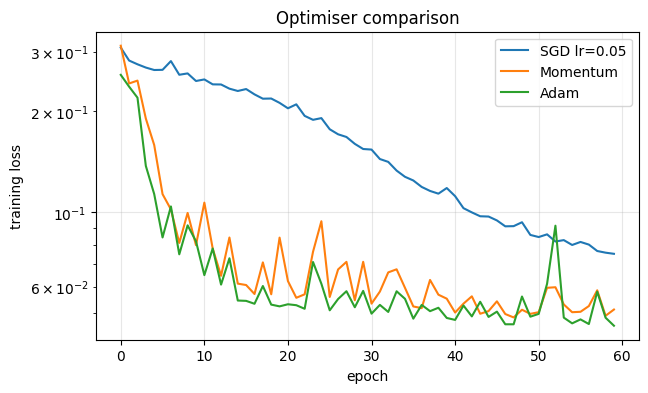

In [10]:
class Momentum:
    def __init__(self, lr=0.05, beta=0.9):
        self.lr, self.beta, self.v = lr, beta, {}
    def __call__(self, net):
        for i, (layer, P, g) in enumerate(net.params()):
            self.v[i] = self.beta * self.v.get(i, 0) + getattr(layer, g)
            P -= self.lr * self.v[i]

class Adam:
    def __init__(self, lr=0.01, b1=0.9, b2=0.999, eps=1e-8):
        self.lr, self.b1, self.b2, self.eps, self.t, self.m, self.v = lr, b1, b2, eps, 0, {}, {}
    def __call__(self, net):
        self.t += 1
        for i, (layer, P, g) in enumerate(net.params()):
            G = getattr(layer, g)
            self.m[i] = self.b1 * self.m.get(i, 0) + (1 - self.b1) * G
            self.v[i] = self.b2 * self.v.get(i, 0) + (1 - self.b2) * G ** 2
            m_hat = self.m[i] / (1 - self.b1 ** self.t)      # bias correction for the first steps
            v_hat = self.v[i] / (1 - self.b2 ** self.t)
            P -= self.lr * m_hat / (np.sqrt(v_hat) + self.eps)

results = {}
for name, opt in [("SGD lr=0.05", lambda n: sgd_step(n, 0.05)), ("Momentum", Momentum()), ("Adam", Adam())]:
    np.random.seed(0)
    results[name], _ = train(MLP([2, 32, 32, 2]), opt, epochs=60)
for name, h in results.items():
    plt.plot(h, label=name)
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("training loss"); plt.legend(); plt.title("Optimiser comparison"); plt.show()

## 10. Initialisation and learning rate

**Initialisation.** If weights are too small, activations shrink layer after layer until the signal (and the gradient) vanishes. Too large, and they explode. **He initialisation** ($\mathcal{N}(0, 2/n_{in})$) keeps the variance of ReLU activations roughly constant through depth. The plot shows activation spread across a 10-layer network for three choices.

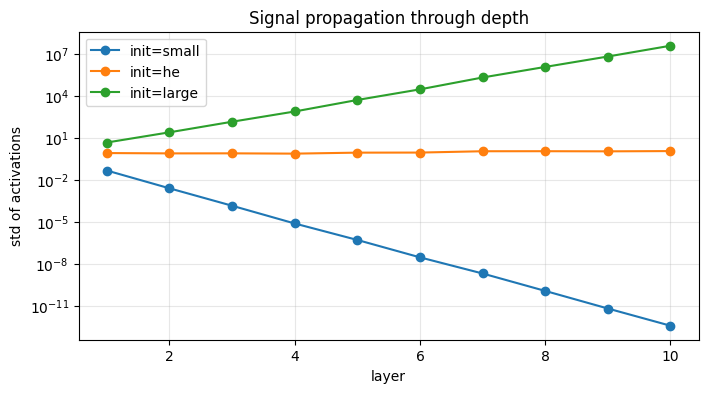

In [11]:
Xs = np.random.randn(500, 64)
fig, ax = plt.subplots(figsize=(8, 4))
for init in ["small", "he", "large"]:
    np.random.seed(0)
    deep = MLP([64] * 11 + [2], init=init)
    A, stds = Xs, []
    for layer in deep.layers[:-1]:
        A = layer.forward(A)
        if isinstance(layer, ReLU):
            stds.append(A.std())
    ax.semilogy(range(1, len(stds) + 1), stds, marker="o", label=f"init={init}")
ax.set_xlabel("layer"); ax.set_ylabel("std of activations"); ax.legend(); ax.set_title("Signal propagation through depth")
plt.show()

**Learning rate** is the most important hyperparameter. Too small: slow. Too large: the loss oscillates or diverges.

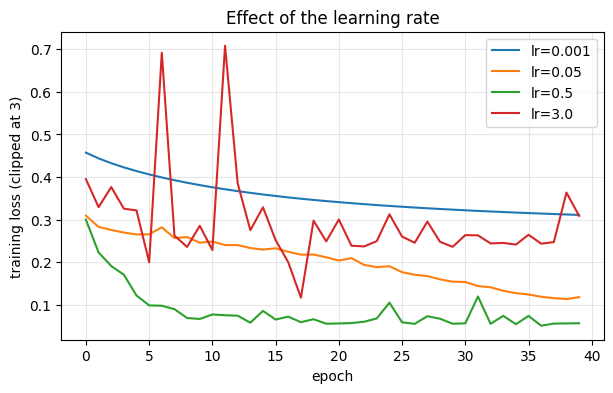

In [12]:
for lr in [0.001, 0.05, 0.5, 3.0]:
    np.random.seed(0)
    h, _ = train(MLP([2, 32, 32, 2]), lambda n, lr=lr: sgd_step(n, lr), epochs=40)
    plt.plot(np.clip(h, 0, 3), label=f"lr={lr}")
plt.xlabel("epoch"); plt.ylabel("training loss (clipped at 3)"); plt.legend(); plt.title("Effect of the learning rate"); plt.show()

## 11. Cross-check with PyTorch autograd

We copy our NumPy network's weights into PyTorch, run the same batch, and compare gradients. They match to floating-point precision: `loss.backward()` is the algorithm we just wrote.

In [13]:
import torch
np.random.seed(0)
ours = MLP([2, 16, 16, 2])
Xb, yb = Xtr[:64], ytr[:64]
ours.loss(Xb, yb); ours.backward()

lin = [l for l in ours.layers if isinstance(l, Linear)]
tparams = [(torch.tensor(l.W, requires_grad=True), torch.tensor(l.b, requires_grad=True)) for l in lin]
h = torch.tensor(Xb)
for i, (W, b) in enumerate(tparams):
    h = h @ W.T + b
    if i < len(tparams) - 1:
        h = torch.relu(h)
loss = torch.nn.functional.cross_entropy(h, torch.tensor(yb))
loss.backward()
for i, (l, (W, b)) in enumerate(zip(lin, tparams)):
    print(f"layer {i}: max |dW ours - dW torch| = {np.abs(l.dW - W.grad.numpy()).max():.2e}, "
          f"max |db diff| = {np.abs(l.db - b.grad.numpy()).max():.2e}")

layer 0: max |dW ours - dW torch| = 2.78e-17, max |db diff| = 2.78e-17
layer 1: max |dW ours - dW torch| = 1.11e-16, max |db diff| = 2.78e-17
layer 2: max |dW ours - dW torch| = 1.11e-16, max |db diff| = 1.11e-16


## Key takeaways

* A network is layers of neurons; a layer is a matrix multiply plus a non-linearity.
* **Backpropagation** applies the chain rule backwards through the computational graph; one backward pass yields every gradient.
* Gradients for a linear layer: $dW = G^\top X$, $db=\sum G$, $dX = GW$. Activations multiply by $f'(z)$ element-wise.
* Always **gradient-check** hand-written backward passes.
* **Adam** + **He init** + a sane **learning rate** make training reliable.
* PyTorch automates exactly this, which is what we use in notebooks 03 to 09.

## Exercises

1. Add a `Sigmoid` layer class and train the two-moons network with it. Compare to ReLU and Tanh.
2. Add **L2 weight decay** to `sgd_step` ($P \leftarrow P - \eta(\nabla + \lambda P)$). How does the decision boundary change for a large $\lambda$?
3. Add a `__truediv__` and `exp` method to `Value` and implement softmax with the scalar engine.
4. Train on `sklearn.datasets.make_circles`. What is the smallest hidden layer that solves it?
5. Implement **dropout** as a layer (random mask in training, identity at test time).